In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import random

import numpy as np
from pathlib import Path
import logging

import torch
import mlflow
import matplotlib.pyplot as plt

from dotenv import load_dotenv
import mlflow
import networkx as nx
from halcyon.Simulators import SimulationResult

# Making some plots to show the network topologies

## The 20, 50, 100 genes normally

In [2]:
seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

In [ ]:
sim_runs = mlflow.search_runs(
    experiment_ids=["7"],
    filter_string="tags.run_type = 'dataset' and params.noise_level = 'MEDIUM'",
)
# Start with smallest network first
sim_runs["params.nr_genes"] = sim_runs["params.nr_genes"].astype(int)
sim_runs = sim_runs.sort_values("params.nr_genes", ascending=True)
sim_runs


,run_id,experiment_id,status,artifact_uri,start_time,end_time,params.num_modules,params.sparsity,params.seed,params.noise_level,params.nr_genes,tags.mlflow.user,tags.mlflow.source.git.commit,tags.mlflow.runName,tags.mlflow.source.name,tags.run_type,tags.mlflow.source.type
2,6a8078c2c7764850b1fb8b3c33553a1b,7,FINISHED,mlflow-artifacts:/7/6a8078c2c7764850b1fb8b3c33...,2026-04-13 13:46:09.215000+00:00,2026-04-13 13:46:19.546000+00:00,2,0.1,174,MEDIUM,20,ben.noordijk@wur.nl,178691d983c043db25bc1ae7038672c3106c6ed4,dataset_genes20_sparsity0.1_nr_modules2_noiseM...,scripts/motivate_ml_and_mm_choice_mlflow_id_4/...,dataset,LOCAL
1,f02bf732b2ba4817b254bd5174f1549b,7,FINISHED,mlflow-artifacts:/7/f02bf732b2ba4817b254bd5174...,2026-04-13 13:47:05.368000+00:00,2026-04-13 13:47:15.803000+00:00,5,0.1,174,MEDIUM,50,ben.noordijk@wur.nl,178691d983c043db25bc1ae7038672c3106c6ed4,dataset_genes50_sparsity0.1_nr_modules5_noiseM...,scripts/motivate_ml_and_mm_choice_mlflow_id_4/...,dataset,LOCAL
0,f862625665764f1383bf88e5615594dc,7,FINISHED,mlflow-artifacts:/7/f862625665764f1383bf88e561...,2026-04-13 13:49:07.756000+00:00,2026-04-13 13:49:18.541000+00:00,10,0.1,174,MEDIUM,100,ben.noordijk@wur.nl,178691d983c043db25bc1ae7038672c3106c6ed4,dataset_genes100_sparsity0.1_nr_modules10_nois...,scripts/motivate_ml_and_mm_choice_mlflow_id_4/...,dataset,LOCAL


In [5]:
sim_output_list: list[SimulationResult] = []
for sim_run_id in sim_runs["run_id"]:
    run = mlflow.get_run(sim_run_id)
    params = run.data.params
    logging.info(f"Loaded run with params: {params}")

    # Load data
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=sim_run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output_list.append(sim_output)



2026-04-24 14:16:11,879 - INFO - Loaded run with params: {'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '2', 'noise_level': 'MEDIUM', 'seed': '174'}


2026-04-24 14:16:16,102 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,117 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,132 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,146 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,173 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,177 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,205 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:16,210 - WARNING - Connection p

2026-04-24 14:16:20,891 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:20,899 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:20,917 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:20,957 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:20,964 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:20,977 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:20,996 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:21,016 - WARNING - Connection p

2026-04-24 14:16:25,872 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:25,904 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:25,912 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:25,972 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:25,986 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:26,005 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:26,008 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-24 14:16:26,042 - WARNING - Connection p

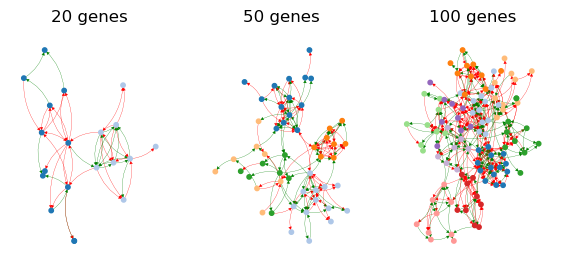

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(7, 3))
for ax, sim_output in zip(axes, sim_output_list):
    sim_output.network.do_clustering()  
    # sim_output.nr_genes
    ax.set_title(f'{sim_output.nr_genes} genes')
    sim_output.network.plot(ax=ax, layout_func=nx.kamada_kawai_layout, with_labels=False, node_size=10, arrowsize=5, width=0.2)
fig.savefig("network_plots.pdf", dpi=300, bbox_inches='tight')